# Figure 1

In [1]:
from pathlib import Path
import sys
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))
from utils.statistics import mean_parcelwise, zeta_score
from utils.surface import plot_parcelwise_with_roi_surface_direct
from utils.network_plots import plot_network_task_radarplot_from_values

In [2]:
import matplotlib as mpl
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

In [3]:
datasets = ["discovery", "replication", "robustness"]
field = "Hursts"
output_path = f"{base_path}/FIGURES/main/Fig_1"

In [4]:
data_dfs = {}

for i, dataset in enumerate(datasets):
    data_path = f"{base_path}/RESULTS/{dataset}_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
    data_df = pd.read_csv(data_path)
    data_dfs[dataset] = data_df

## 1A-C: mean z-scored Hurst maps

In [5]:
# Config
colormap = "coolwarm"
panels = ["A", "B", "C"]

In [6]:
os.makedirs(output_path, exist_ok=True)

for i, dataset in enumerate(datasets):
    data_df = data_dfs[dataset]

    mapname = f'{output_path}/{panels[i]}_mean_{dataset}.png'
    mean_map = mean_parcelwise(data_df, field=field)
    zeta_scores = zeta_score(mean_map)

    plot_parcelwise_with_roi_surface_direct(
            matrix=zeta_scores,
            lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
            rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
            roi_img_path=None,
            img_name=mapname,
            colormap = colormap,
            mesh="fsaverage6",
            inflate_fraction=0.70,
            show=False,
            vmin=-2,
            vmax=2
        )

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6
[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6
[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


In [7]:
for i, dataset in enumerate(datasets):
    data_df = data_dfs[dataset]

    mean_map = mean_parcelwise(data_df, field=field)

    print(f"====== {dataset} dataset ======")

    mean_cont = np.nanmean(data_df[data_df['Network']==('Cont')]['Hursts'])
    mean_default = np.nanmean(data_df[data_df['Network']==('Default')]['Hursts'])
    mean_limbic = np.nanmean(data_df[data_df['Network']==('Limbic')]['Hursts']) 

    std_cont = np.nanstd(data_df[data_df['Network']==('Cont')]['Hursts'])
    std_default = np.nanstd(data_df[data_df['Network']==('Default')]['Hursts'])
    std_limbic = np.nanstd(data_df[data_df['Network']==('Limbic')]['Hursts']) 

    print("CONT = ", mean_cont, "std:", std_cont)
    print("DMN = ", mean_default, "std:", std_default)
    print("LIM = ", mean_limbic, "std:", std_limbic)
    print("\n")

====== discovery dataset ======
CONT =  1.3815970831327635 std: 0.22691215958952257
DMN =  1.3364074719731704 std: 0.22818772247424438
LIM =  1.0840558488942174 std: 0.18563271213003474


====== replication dataset ======
CONT =  1.3604209910238971 std: 0.24814772137213376
DMN =  1.3021236792975006 std: 0.2529280533033757
LIM =  1.1235311126681802 std: 0.2732305985474124


====== robustness dataset ======
CONT =  1.5807296238799244 std: 0.16094507262145535
DMN =  1.576691844878052 std: 0.15405128661191816
LIM =  1.3865599299323883 std: 0.13063241786994353




## 1D: Radar plot

In [20]:
network_labels = ["LIM", "SMN", "DAN", "VAN", "VIS", "CONT", "DMN"]

network_mapping = {
    "Limbic": "LIM",
    "DorsAttn": "DAN",
    "Cont": "CONT",
    "Vis": "VIS",
    "SalVentAttn": "VAN",
    "Default": "DMN",
    "SomMot": "SMN"
}

task_colors = [
    "#003674",
    "#ff5e69",
    "#D19722"
]

order = "ascending"
LABELSIZE = 30
TICKSIZE = 20

Network order:
LIM: -1.899
VAN: -0.459
VIS: 0.030
SMN: 0.185
DMN: 0.405
CONT: 0.805
DAN: 0.931


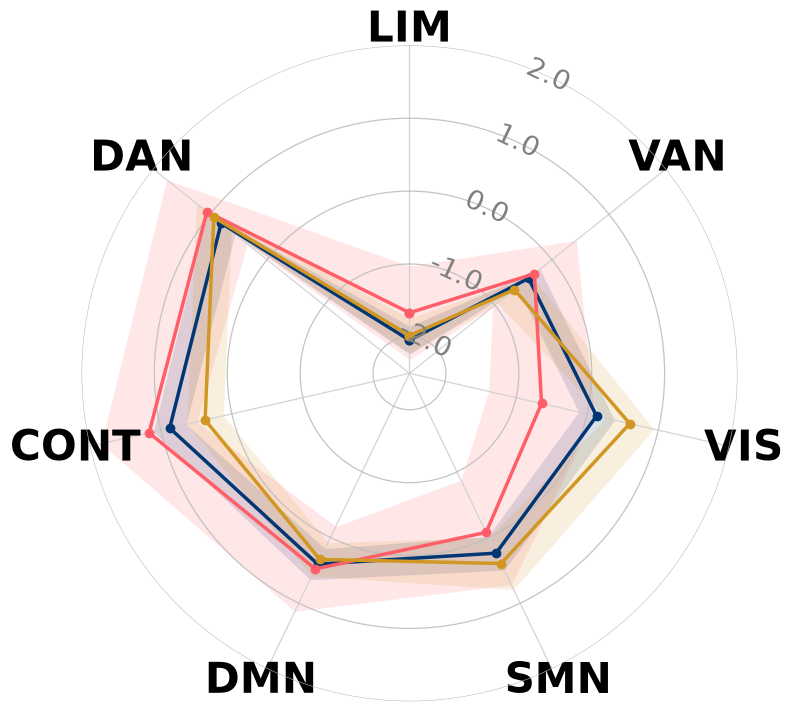

In [21]:
from scipy.stats import t

networks = np.array(network_labels)
means = []
CIs = []

for dataset in datasets:
    data_df = data_dfs[dataset].copy()
    data_df["Network"] = data_df["Network"].replace(network_mapping)

    subject_network = (
        data_df.groupby(["Subject", "Network"])[field]
        .mean()
        .unstack()
        .reindex(columns=network_labels)
    )

    mean = subject_network.mean(axis=0).to_numpy()
    std = subject_network.std(axis=0, ddof=1).to_numpy()
    n = subject_network.count().to_numpy()

    if np.any(n < 2):
        raise ValueError(f"{dataset}: fewer than 2 subjects for a network")

    CI = t.ppf(0.975, df=n - 1) * std / np.sqrt(n)

    means.append(mean)
    CIs.append(CI)

values_arr = np.asarray(means, dtype=float)
std_arr = np.asarray(CIs, dtype=float)

z_values = np.zeros_like(values_arr)
z_std_values = np.zeros_like(std_arr)

for i in range(values_arr.shape[0]):

    # Mean and SD across the 7 networks for this dataset
    mu = values_arr[i].mean()
    sigma = values_arr[i].std(ddof=1)

    # Z-score network means
    z_values[i] = (
        values_arr[i] - mu
    ) / sigma

    # Error bars transform only by the scaling factor
    z_std_values[i] = (
        std_arr[i] / sigma
    )

# Convert back to lists if the plotting function expects lists
z_values_arr = np.asarray(z_values, dtype=float)
z_std_arr = np.asarray(z_std_values, dtype=float)

# Mean across the three datasets for each network
network_mean = z_values_arr.mean(axis=0)

if order == "ascending":
    order_idx = np.argsort(network_mean)

elif order == "descending":
    order_idx = np.argsort(-network_mean)

else:
    raise ValueError("order must be 'ascending' or 'descending'")

# Reorder everything consistently
networks_ordered = networks[order_idx].tolist()

z_values_ordered = z_values_arr[:, order_idx].tolist()
z_std_values_ordered = z_std_arr[:, order_idx].tolist()

# Optional check
print("Network order:")
for network, mean_value in zip(
    networks_ordered,
    network_mean[order_idx]
):
    print(f"{network}: {mean_value:.3f}")

plot_network_task_radarplot_from_values(
    values=z_values_ordered,
    networks=networks_ordered,
    std_values=z_std_values_ordered,
    tasks=datasets,
    task_colors=task_colors,
    figsize=(8, 8),
    ymin=-2.5,
    ymax=2.0,
    LABELSIZE=LABELSIZE,
    TICKSIZE=TICKSIZE,
    yticks=[-2, -1, 0, 1, 2],
    save_path=f"{output_path}/D_radarplot.png"
)


## 1E: Voxel mean values

In [8]:
# discovery dataset

discovery_ei_path = f"{base_path}/DATA/discovery_dataset/cleaned_MRS_df.csv"
discovery_h_path = f"{base_path}/RESULTS/discovery_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
discovery_parcels_path = f"{base_path}/DATA/discovery_dataset/selected_parcels_overlap30.csv"

# replication dataset

replication_ei_path = f"{base_path}/DATA/replication_dataset/EIB_12s_MRS_static_&_AUC_New_criteria.csv"
replication_h_path = f"{base_path}/RESULTS/replication_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
replication_parcels_path = f"{base_path}/DATA/replication_dataset/selected_parcels_overlap30.csv"


In [9]:
from matplotlib.colors import LinearSegmentedColormap

max_color_discovery = "#003674"
min_color_discovery = "#A3CEFF"
max_color_replication = "#ff5e69"
min_color_replication = "#FFFFFF"

colors = [min_color_discovery, max_color_discovery]
cmap_custom_discovery = LinearSegmentedColormap.from_list(
    "custom",
    colors,
    N=256
)

colors = [min_color_replication, max_color_replication]
cmap_custom_replication = LinearSegmentedColormap.from_list(
    "custom",
    colors,
    N=256
)

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


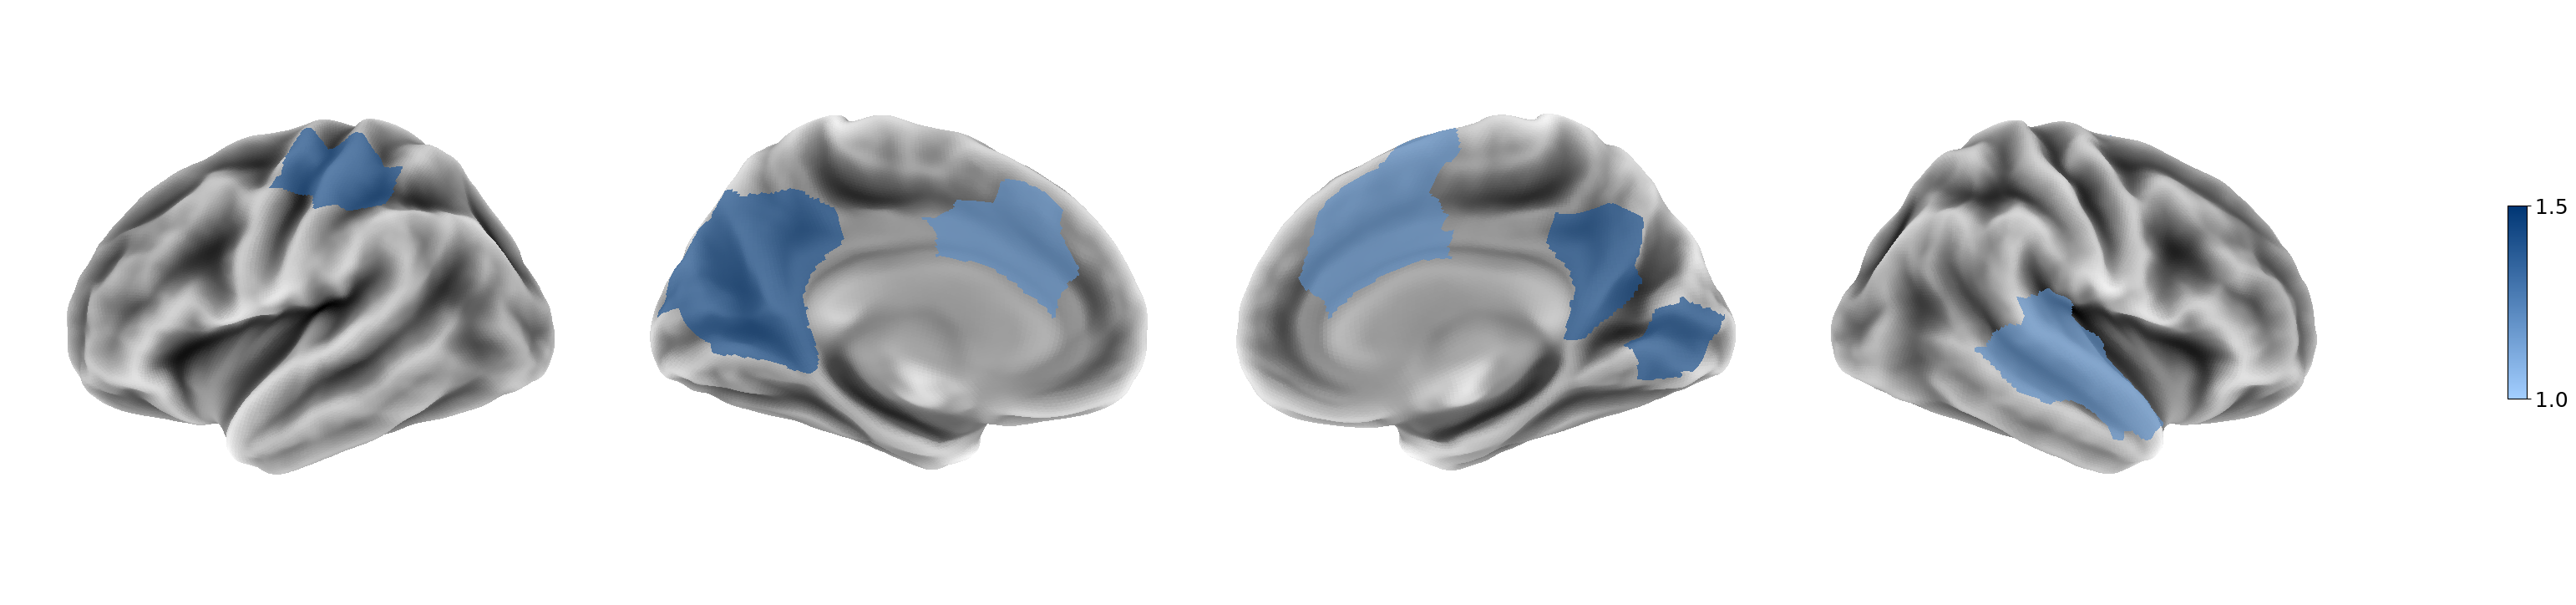

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


/home/matilde/miniconda3/envs/hurst-neuroimaging/lib/python3.11/site-packages/nilearn/plotting/_utils.py:262: RuntimeWarning: All-NaN slice encountered
  data_min = np.nanmin(data)
/home/matilde/miniconda3/envs/hurst-neuroimaging/lib/python3.11/site-packages/nilearn/plotting/_utils.py:265: RuntimeWarning: All-NaN slice encountered
  data_max = np.nanmax(data)


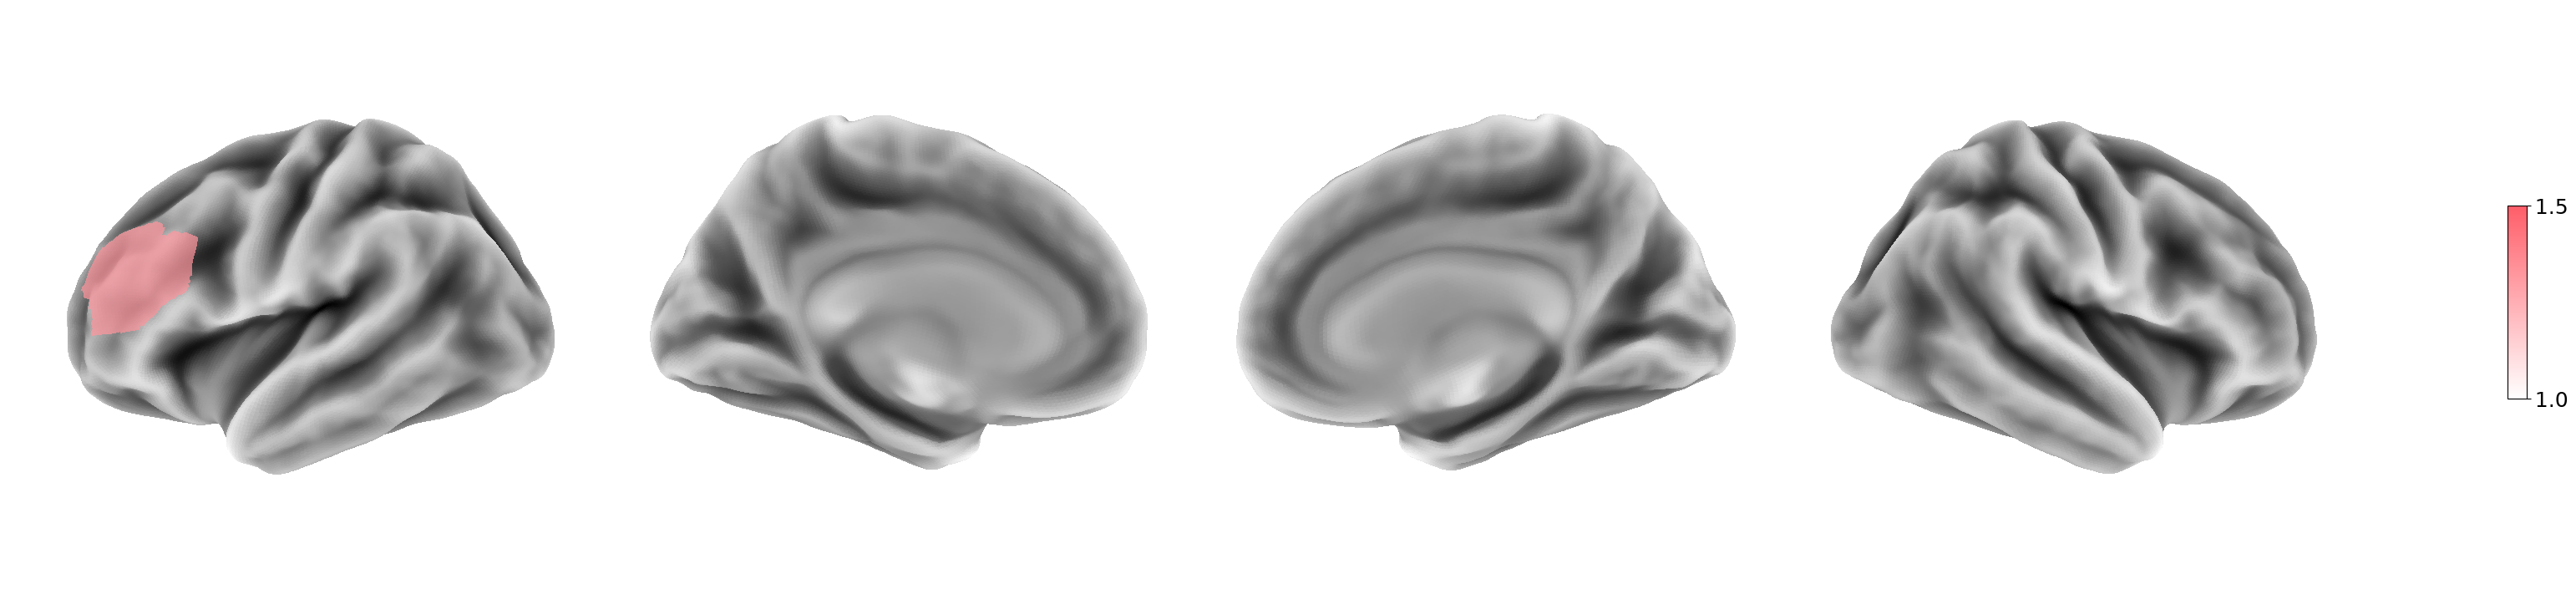

In [10]:
# discovery dataset - H

discovery_h_df = pd.read_csv(discovery_h_path)
discovery_parcels_df = pd.read_csv(discovery_parcels_path)

all_parcel_ids = np.sort(
    discovery_parcels_df["parcel_id"].dropna().astype(int).unique()
)

all_voxel_hurst = np.full(100, np.nan)

for voxel in discovery_parcels_df["voxel"].dropna().unique():
    voxel_df = discovery_parcels_df[discovery_parcels_df["voxel"] == voxel]

    voxel_parcel_ids = np.sort(
        voxel_df["parcel_id"].dropna().astype(int).unique()
    )

    voxel_parcel_index = voxel_parcel_ids - 1

    voxel_hurst_values = discovery_h_df.loc[
        discovery_h_df["Parcel"].isin(voxel_parcel_ids),
        "Hursts"
    ].values

    mean_voxel_hurst = np.nanmean(voxel_hurst_values)
    all_voxel_hurst[voxel_parcel_index] = mean_voxel_hurst

mapname = os.path.join(output_path, "E_discovery_H.png")

plot_parcelwise_with_roi_surface_direct(
    matrix=all_voxel_hurst,
    lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
    rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
    roi_img_path=None,
    colormap= cmap_custom_discovery,
    img_name=mapname,
    mesh="fsaverage6",
    inflate_fraction=0.70,
    show=True,
    vmin=1,
    vmax=1.5,
)


# replication dataset - H

replication_h_df = pd.read_csv(replication_h_path)
replication_parcels_df = pd.read_csv(replication_parcels_path)

all_parcel_ids = np.sort(
    replication_parcels_df["parcel_id"].dropna().astype(int).unique()
)

all_voxel_hurst = np.full(100, np.nan)

for voxel in replication_parcels_df["voxel"].dropna().unique():
    voxel_df = replication_parcels_df[replication_parcels_df["voxel"] == voxel]

    voxel_parcel_ids = np.sort(
        voxel_df["parcel_id"].dropna().astype(int).unique()
    )

    voxel_parcel_index = voxel_parcel_ids - 1

    voxel_hurst_values = replication_h_df.loc[
        replication_h_df["Parcel"].isin(voxel_parcel_ids),
        "Hursts"
    ].values

    mean_voxel_hurst = np.nanmean(voxel_hurst_values)
    all_voxel_hurst[voxel_parcel_index] = mean_voxel_hurst

mapname = os.path.join(output_path, "E_replication_H.png")

plot_parcelwise_with_roi_surface_direct(
    matrix=all_voxel_hurst,
    lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
    rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
    roi_img_path=None,
    colormap= cmap_custom_replication,
    img_name=mapname,
    mesh="fsaverage6",
    inflate_fraction=0.70,
    show=True,
    vmin=1,
    vmax=1.5,
)

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


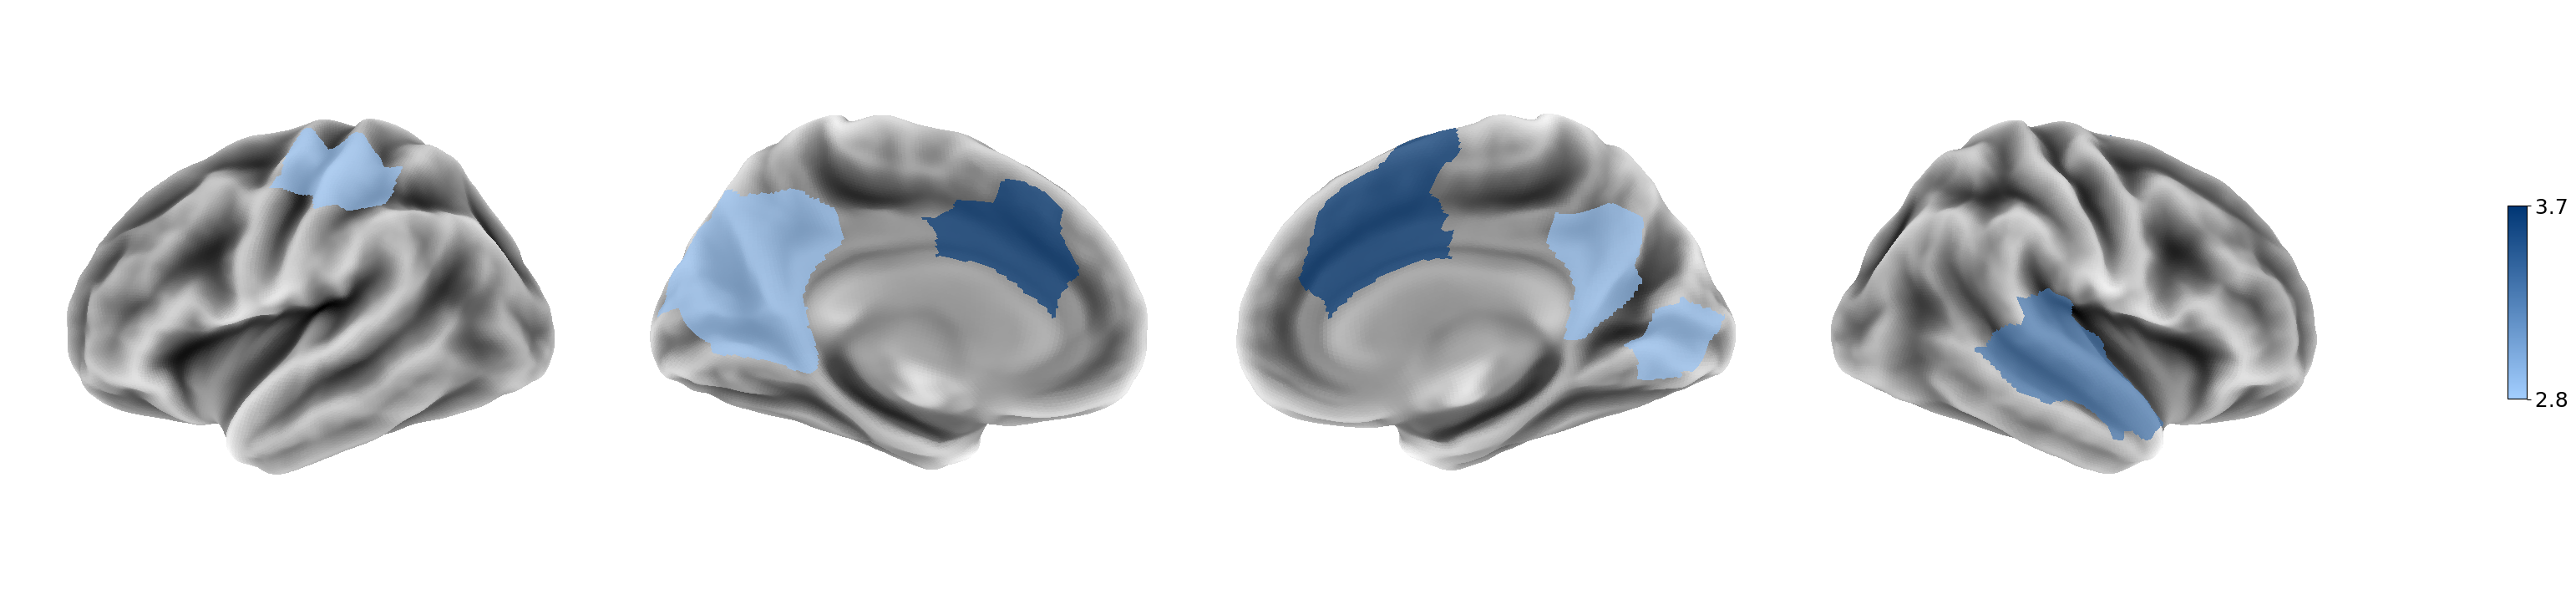

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


/home/matilde/miniconda3/envs/hurst-neuroimaging/lib/python3.11/site-packages/nilearn/plotting/_utils.py:262: RuntimeWarning: All-NaN slice encountered
  data_min = np.nanmin(data)
/home/matilde/miniconda3/envs/hurst-neuroimaging/lib/python3.11/site-packages/nilearn/plotting/_utils.py:265: RuntimeWarning: All-NaN slice encountered
  data_max = np.nanmax(data)


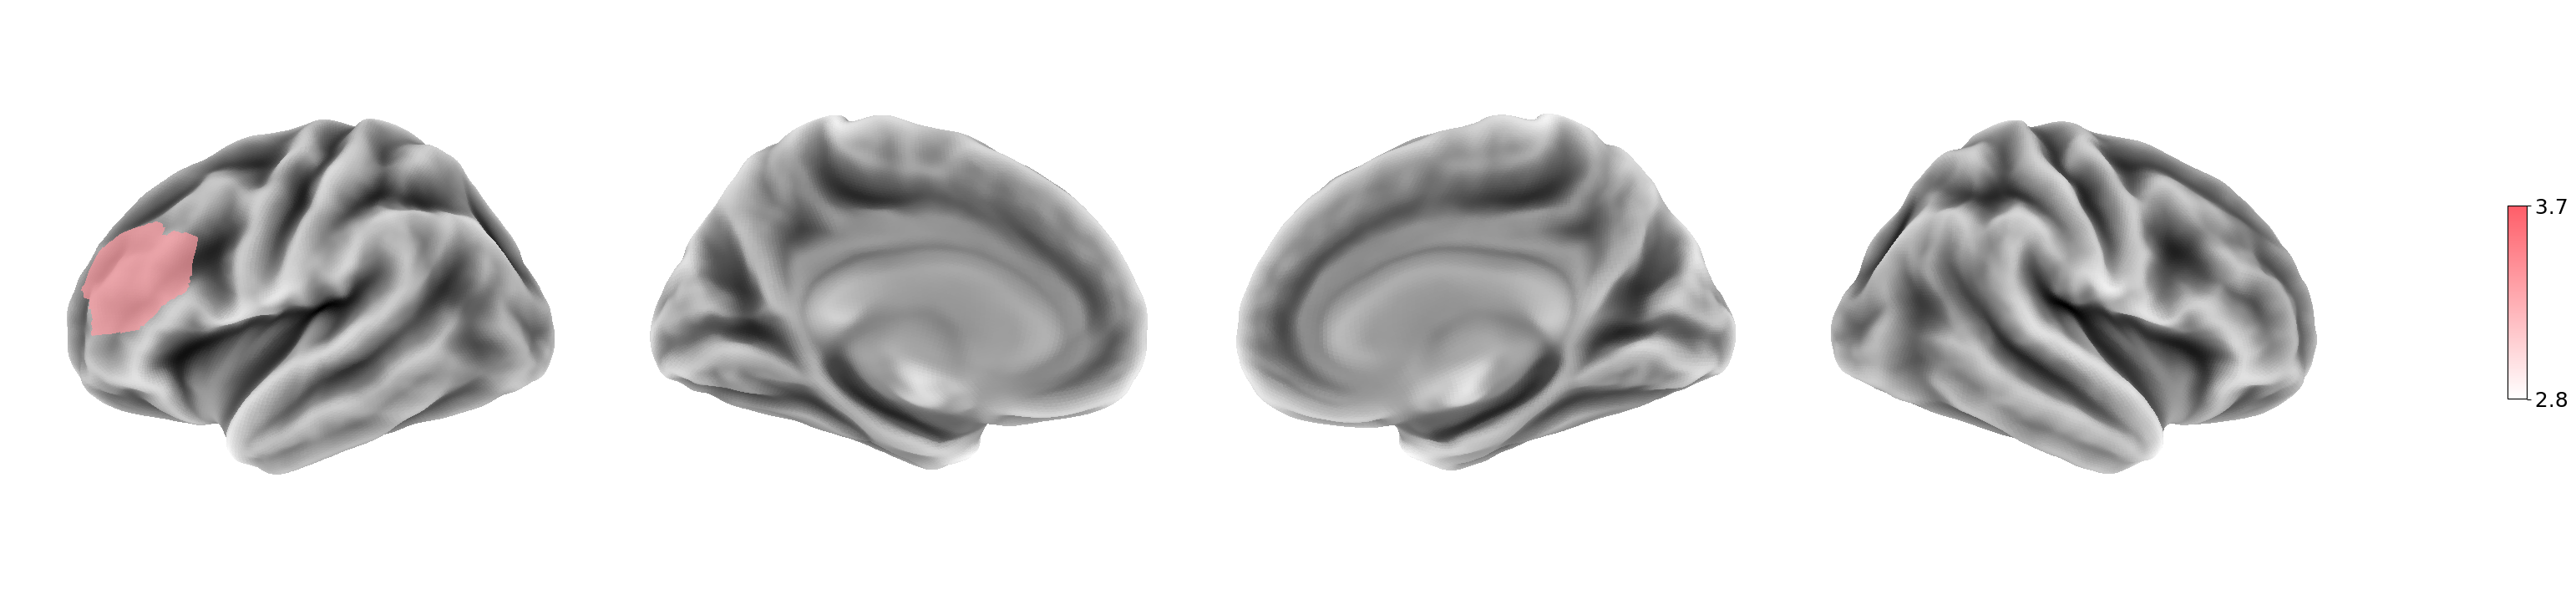

In [16]:
# Discovery dataset - EIB

mrs_df = pd.read_csv(discovery_ei_path)
selected_parcels = pd.read_csv(discovery_parcels_path)

all_parcel_ids = np.sort(
    selected_parcels["parcel_id"].dropna().astype(int).unique()
)

all_voxel_mrs = np.full(100, np.nan)

for voxel in selected_parcels["voxel"].dropna().unique():
    voxel_df = selected_parcels[selected_parcels["voxel"] == voxel]

    voxel_parcel_ids = np.sort(
        voxel_df["parcel_id"].dropna().astype(int).unique()
    )

    voxel_parcel_index = voxel_parcel_ids - 1

    voxel_mrs_values = mrs_df.loc[
        mrs_df["Voxel"] == voxel,
        "GlxGABA_AlphaTissCorr"
    ].values

    mean_voxel_mrs = np.nanmean(voxel_mrs_values)
    all_voxel_mrs[voxel_parcel_index] = mean_voxel_mrs

mapname = os.path.join(output_path, "E_discovery_EIB.png")

plot_parcelwise_with_roi_surface_direct(
    matrix=all_voxel_mrs,
    lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
    rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
    roi_img_path=None,
    colormap=cmap_custom_discovery,
    img_name=mapname,
    mesh="fsaverage6",
    inflate_fraction=0.70,
    show=True,
    vmin=2.8,
    vmax=3.7
)

# Replication dataset - EIB
mrs_df = pd.read_csv(replication_ei_path)
selected_parcels = pd.read_csv(replication_parcels_path)

all_parcel_ids = np.sort(
    selected_parcels["parcel_id"].dropna().astype(int).unique()
)

all_voxel_mrs = np.full(100, np.nan)
voxel_parcel_ids = np.sort(
    selected_parcels["parcel_id"].dropna().astype(int).unique()
)

voxel_parcel_index = voxel_parcel_ids - 1

mrs_df = mrs_df[mrs_df["Runs"]=="ARest"].copy()
voxel_mrs_values = mrs_df["EIB"].values

mean_voxel_mrs = np.nanmean(voxel_mrs_values)
all_voxel_mrs[voxel_parcel_index] = mean_voxel_mrs

mapname = os.path.join(output_path, "E_replication_EIB.png")

plot_parcelwise_with_roi_surface_direct(
    matrix=all_voxel_mrs,
    lh_annot_path=f"{base_path}/DATA/templates/lh.Schaefer2018_100Parcels_7Networks_order.annot",
    rh_annot_path=f"{base_path}/DATA/templates/rh.Schaefer2018_100Parcels_7Networks_order.annot",
    roi_img_path=None,
    colormap= cmap_custom_replication,
    img_name=mapname,
    mesh="fsaverage6",
    inflate_fraction=0.70,
    show=True,
    vmin=2.8,
    vmax=3.7
)

## 1F: Boxplots

In [5]:
# helper function for plotting
def plot_boxplot_and_scatter_ordered(data, labels, order="ascending"):

    rng = np.random.default_rng(42)

    # Order voxels by median, keeping the first voxel fixed
    if order not in ["ascending", "descending"]:
        raise ValueError("order must be 'ascending' or 'descending'")

    remaining_idx = list(range(1, len(data)))

    remaining_idx = sorted(
        remaining_idx,
        key=lambda i: np.nanmedian(data[i]),
        reverse=(order == "descending")
    )

    idx_order = [0] + remaining_idx

    data_ordered = [data[i] for i in idx_order]
    colors_ordered = [voxel_colors[i] for i in idx_order]
    labels_ordered = [labels[i] for i in idx_order]

    # Plot
    x = np.arange(1, len(labels_ordered) + 1)

    for i in range(len(labels_ordered)):

        vals = data_ordered[i]
        x0 = x[i]

        jitter = rng.uniform(
            -0.09,
            0.09,
            size=len(vals)
        )

        ax.scatter(
            np.full(len(vals), x0) + jitter,
            vals,
            s=50,
            color=colors_ordered[i],
            alpha=0.2,
            edgecolors="none",
            zorder=3
        )

    # boxplot
    bp = ax.boxplot(
        data_ordered,
        positions=x,
        widths=0.55,
        patch_artist=True,
        showmeans=False,
        medianprops=dict(
            color="black",
            linewidth=2
        ),
        boxprops=dict(
            linewidth=1.2
        ),
        whiskerprops=dict(
            linewidth=1.2,
            color="0.25"
        ),
        capprops=dict(
            linewidth=1.2,
            color="0.25"
        ),
        flierprops=dict(
            marker="o",
            markersize=3,
            markerfacecolor="0.4",
            markeredgecolor="0.4",
            alpha=0.25
        ),
    )

    for patch, c in zip(bp["boxes"], colors_ordered):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
        patch.set_edgecolor("k")

    # x-axis labels in the same order
    ax.set_xticks(x)
    ax.set_xticklabels(labels_ordered)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", alpha=0.2)

    grey = "#6A6A6A"

    for spine in ["bottom", "left"]:
        ax.spines[spine].set_color(grey)

In [6]:
voxel_labels = ['lDLPFC', 'ACC', 'OCC', 'rAUD', 'lSMN']

## colormap for the voxels ##
max_color = "#003674"

base_rgb = np.array(mpl.colors.to_rgb(max_color))
lighten = np.linspace(0.0, 0.65, 4)

max_color_cmap = mpl.colors.ListedColormap(
    [tuple(base_rgb * (1 - t) + t) for t in lighten],
    name="max_color_cmap"
)
voxel_colors = ['#ff5e69'] + list(max_color_cmap.colors)

figsize = (8, 7)
LABEL_FS = 35
TICK_FS = 35

### Glx/GABA+

In [7]:
discovery_ei_path = f"{base_path}/DATA/discovery_dataset/cleaned_MRS_df.csv"
replication_ei_path = f"{base_path}/DATA/replication_dataset/EIB_12s_MRS_static_&_AUC_New_criteria.csv"

In [8]:
discovery_ei_df = pd.read_csv(discovery_ei_path)
replication_ei_df = pd.read_csv(replication_ei_path)
data = []

# prepare replication data
replication_ei_df = replication_ei_df[replication_ei_df['EIB_eligible'] == True]
data.append(replication_ei_df["EIB"].values)

# prepare discovery data
voxel_names = discovery_ei_df['Voxel'].unique()

for voxel in voxel_names:
    voxel_df = discovery_ei_df[discovery_ei_df['Voxel'] == voxel]
    eib = voxel_df["GlxGABA_AlphaTissCorr"].values
    data.append(eib)

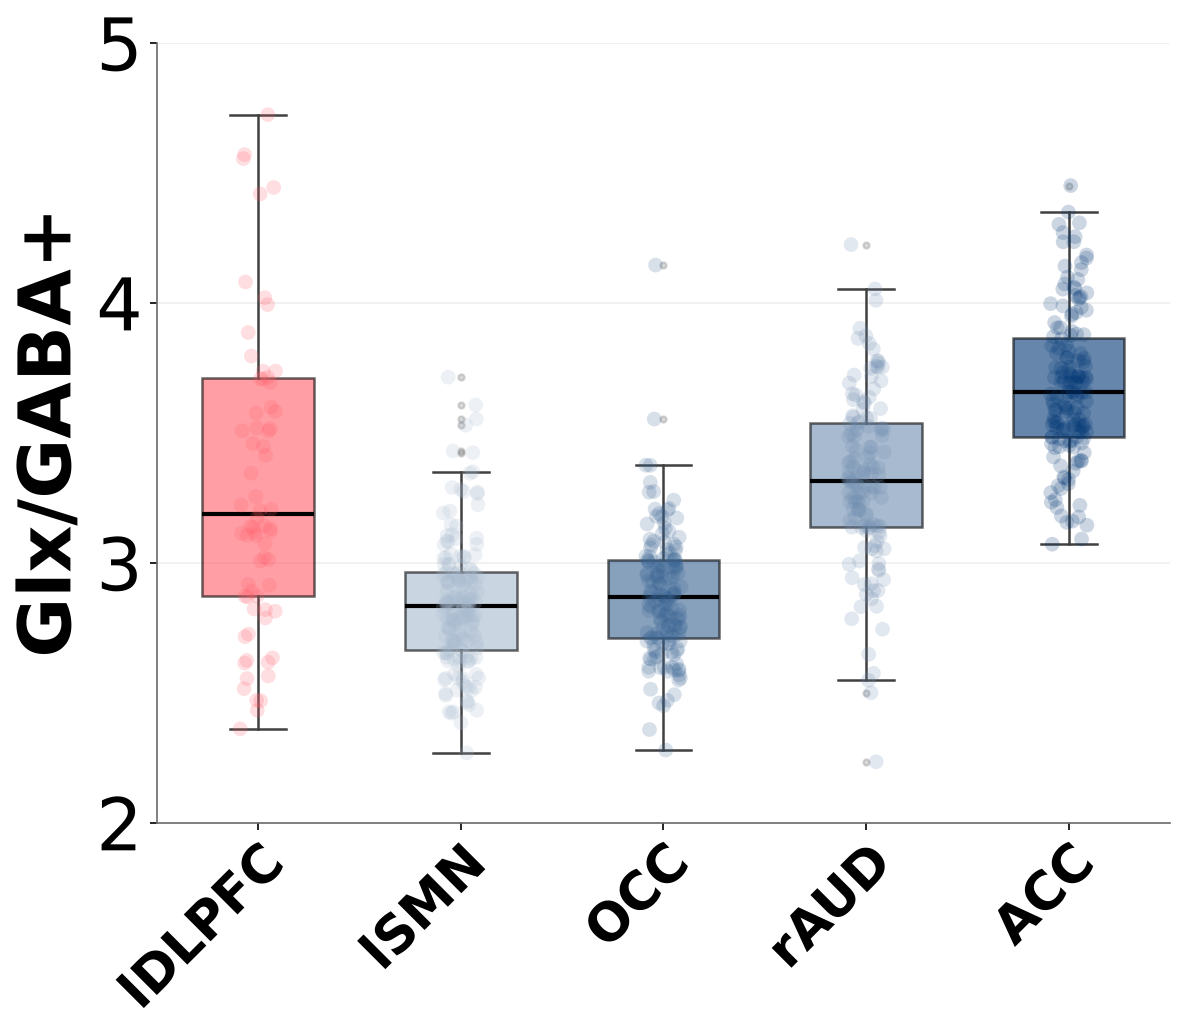

In [9]:
# plot
ffig, ax = plt.subplots(figsize=figsize, dpi=150)

plot_boxplot_and_scatter_ordered(data, labels=voxel_labels, order="ascending")

# aesthetics
ax.tick_params(axis="x", labelsize=TICK_FS - 10)
plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontweight="bold",
    rotation_mode="anchor"
)
ax.set_ylabel("Glx/GABA+", fontsize=LABEL_FS, fontweight="bold")
ax.tick_params(axis="y", labelsize=TICK_FS)

ax.set_yticks([2, 3, 4, 5, 6])
ax.set_yticklabels([2, 3, 4, 5, 6], fontsize=TICK_FS)
ax.set_ylim([2, 5])

plt.tight_layout()
plt.show()

ffig.savefig(
    f"{output_path}/F_EI.png",
    dpi=300,
    bbox_inches="tight"
)

### H

In [27]:
discovery_h_path = os.path.join(
    base_path,
    "RESULTS/discovery_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
)

discovery_parcels_path = os.path.join(
    base_path,
    "DATA/discovery_dataset/selected_parcels_overlap30.csv"
)

replication_h_path = os.path.join(
    base_path,
    "RESULTS/replication_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
)

replication_parcels_path = os.path.join(
    base_path,
    "DATA/replication_dataset/selected_parcels_overlap30.csv"
)

field = "Hursts"

voxel_order = [
    "anteriorcingulate",
    "occipital",
    "rightauditory",
    "smleft",
]

In [28]:
def load_hurst_and_parcels(h_path, parcels_path, columns):
    hurst = pd.read_csv(h_path)[[field, "Subject", "Parcel"]].copy()
    parcels = pd.read_csv(parcels_path)
    parcels.columns = parcels.columns.str.lower()
    parcels = parcels.rename(columns={"voxel": "Voxel", "parcel_id": "Parcel"})
    parcels = parcels[columns].copy()

    hurst["Parcel"] = hurst["Parcel"].astype(int)
    parcels["Parcel"] = parcels["Parcel"].astype(int)

    return hurst, parcels


# Load datasets
discovery_h_df, discovery_parcels_df = load_hurst_and_parcels(
    discovery_h_path, discovery_parcels_path, ["Voxel", "Parcel"]
)
discovery_parcels_df = discovery_parcels_df[
    discovery_parcels_df["Voxel"].isin(voxel_order)
].copy()

replication_h_df, replication_parcels_df = load_hurst_and_parcels(
    replication_h_path, replication_parcels_path, ["Parcel"]
)

# Mean Hurst per subject and voxel (Discovery)
discovery_merged = discovery_parcels_df.merge(discovery_h_df, on="Parcel", how="inner")

discovery_mean_df = (
    discovery_merged.groupby(["Subject", "Voxel"], as_index=False)[field].mean()
)

discovery_wide_complete = (
    discovery_mean_df.pivot(index="Subject", columns="Voxel", values=field)
    [voxel_order].dropna().copy()
)

# Mean Hurst per subject (Replication)
replication_merged = replication_parcels_df.merge(replication_h_df, on="Parcel", how="inner")

replication_mean_df = (
    replication_merged.groupby("Subject", as_index=False)["Hursts"].mean()
)

# Boxplot data: Replication first, then Discovery voxels
data = [
    replication_mean_df[field].dropna().values,
    *(discovery_wide_complete[vx].dropna().values for vx in voxel_order)
]

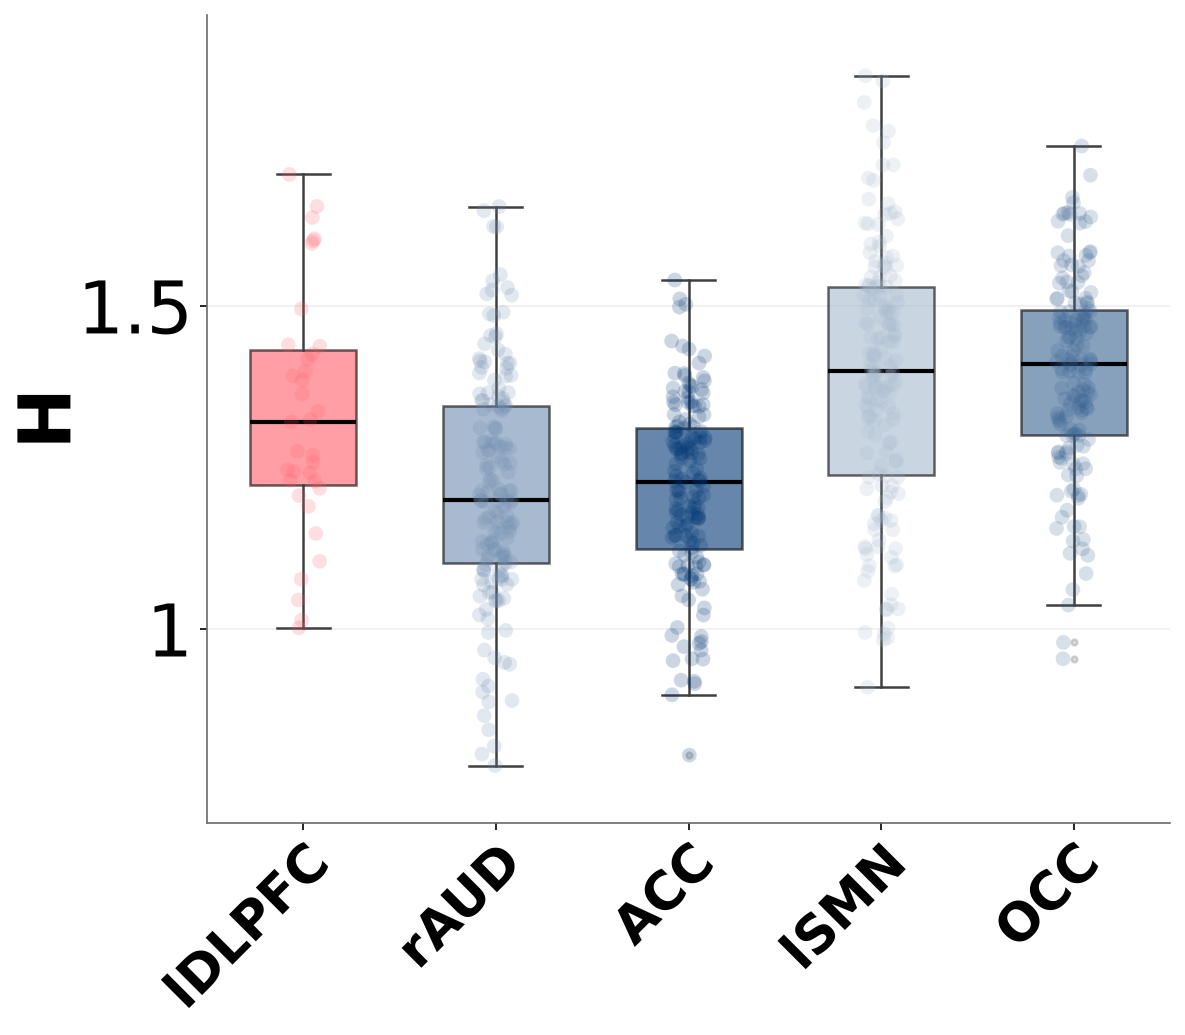

In [29]:
# plot
ffig, ax = plt.subplots(figsize=figsize, dpi=150)

plot_boxplot_and_scatter_ordered(data, labels=voxel_labels, order="ascending")

# aesthetics
x = np.arange(1, len(voxel_labels) + 1)
ax.set_xticks(x)
ax.tick_params(axis="x", labelsize=TICK_FS - 10)
plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontweight="bold",
    rotation_mode="anchor"
)
plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontweight="bold",
    rotation_mode="anchor"
)
ax.set_ylabel("H", fontsize=LABEL_FS, fontweight="bold", labelpad=-5)
ax.tick_params(axis="y", labelsize=TICK_FS)


ax.set_yticks([0.5, 1, 1.5])
ax.set_yticklabels([0.5, 1, 1.5], fontsize=TICK_FS)
ax.set_ylim(0.7, 1.95)

plt.tight_layout()
plt.show()

ffig.savefig(
    f"{output_path}/F_H.png",
    dpi=300,
    bbox_inches="tight"
)


## 1G: Correlations

In [5]:
discovery_path = f"{base_path}/RESULTS/discovery_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
replication_path = f"{base_path}/RESULTS/replication_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"
robustness_path = f"{base_path}/RESULTS/robustness_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest_IQR_cleaned.csv"

In [6]:
from scipy.stats import pearsonr
from itertools import combinations

# Load datasets
datasets = {
    "replication": pd.read_csv(replication_path).query("Task == 'Rest'"),
    "discovery": pd.read_csv(discovery_path),
    "robustness": pd.read_csv(robustness_path)
}

# Use the same parcel ordering across datasets
parcels = sorted(set.intersection(
    *(set(df["Parcel"].unique()) for df in datasets.values())
))

def compute_correlations(df, parcels):
    wide = df.pivot(index="Subject", columns="Parcel", values="Hursts")
    wide = wide.reindex(columns=parcels)

    corr = wide.corr(method="pearson", min_periods=3).to_numpy()

    return corr[np.triu_indices(len(parcels), k=1)]

# Compute parcelwise correlations for each dataset
correlations = {
    name: compute_correlations(df, parcels)
    for name, df in datasets.items()
}

# Compare datasets using valid parcel pairs
results = {}

for a, b in combinations(datasets, 2):
    x, y = correlations[a], correlations[b]
    valid = np.isfinite(x) & np.isfinite(y)

    r, p = pearsonr(x[valid], y[valid])
    results[(a, b)] = (r, p)

    print(f"{a} vs {b}: r = {r:.3f}, p = {p:.3e}")

replication vs discovery: r = 0.306, p = 1.039e-107
replication vs robustness: r = 0.353, p = 8.153e-145
discovery vs robustness: r = 0.525, p = 0.000e+00


In [39]:
# Spin permutation tests

from pathlib import Path
from nibabel.freesurfer import read_annot
from nilearn.datasets import fetch_surf_fsaverage
from brainspace.null_models import SpinPermutations
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import nibabel as nib

# Configuration
N_SPINS = 10_000
SEED = 42

atlas_dir = Path(base_path) / "DATA/templates"
output_dir = Path(base_path) / "RESULTS/spin_tests_correlations"
output_dir.mkdir(parents=True, exist_ok=True)

# Spin tests require the full Schaefer-100 atlas in the correct order
assert list(parcels) == list(range(1, 101)), \
    "Expected Schaefer parcels 1–100 in ascending order."

n_parcels = len(parcels)
iu = np.triu_indices(n_parcels, k=1)


# 1. Spherical centroids (Schaefer-100, fsaverage6)
fsavg = fetch_surf_fsaverage(mesh="fsaverage6")
atlas_name = "Schaefer2018_100Parcels_7Networks_order"

atlas_table = pd.read_csv(
    atlas_dir / f"{atlas_name}_FSLMNI152_2mm.Centroid_RAS.csv"
)
atlas_table.columns = atlas_table.columns.str.strip()

def normalize_name(name):
    if isinstance(name, bytes):
        name = name.decode("utf-8")
    return str(name).strip().split("7Networks_")[-1]

roi_lookup = {
    normalize_name(name): int(parcel)
    for parcel, name in zip(
        atlas_table["ROI Label"], atlas_table["ROI Name"]
    )
}

assert len(roi_lookup) == n_parcels
assert set(roi_lookup.values()) == set(parcels)

coords = np.full((n_parcels, 3), np.nan)
hemiid = np.full(n_parcels, -1)

for hemi_idx, hemi in enumerate(["lh", "rh"]):
    labels, _, names = read_annot(
        str(atlas_dir / f"{hemi}.{atlas_name}.annot")
    )

    sphere = fsavg[
        "sphere_left" if hemi == "lh" else "sphere_right"
    ]
    vertices = np.asarray(nib.load(str(sphere)).darrays[0].data)

    assert len(labels) == len(vertices)

    for label_id, raw_name in enumerate(names):
        mask = labels == label_id
        if not mask.any():
            continue

        name = normalize_name(raw_name)
        if name not in roi_lookup:
            if "background" in name.lower() or "medial_wall" in name.lower():
                continue
            raise ValueError(f"Unknown atlas parcel: {name}")

        expected = "LH_" if hemi == "lh" else "RH_"
        assert name.startswith(expected), f"Hemisphere mismatch: {name}"

        idx = roi_lookup[name] - 1
        assert np.isnan(coords[idx]).all(), f"Duplicate parcel {idx + 1}"

        points = vertices[mask].astype(float)
        points /= np.linalg.norm(points, axis=1, keepdims=True)
        center = points.mean(axis=0)
        coords[idx] = center / np.linalg.norm(center)
        hemiid[idx] = hemi_idx

assert np.isfinite(coords).all(), "Missing spherical centroids."
assert (hemiid == 0).sum() == (hemiid == 1).sum() == 50


# 2. Generate spin permutations
lh_idx = np.where(hemiid == 0)[0]
rh_idx = np.where(hemiid == 1)[0]

spinner = SpinPermutations(
    n_rep=N_SPINS,
    random_state=SEED,
    unique=True,
    surface_algorithm="FreeSurfer"
)

spinner.fit(coords[lh_idx], points_rh=coords[rh_idx])

# Global indices, one permutation per row
spins = np.empty((N_SPINS, n_parcels), dtype=int)
spins[:, lh_idx] = lh_idx[spinner.spin_lh_]
spins[:, rh_idx] = rh_idx[spinner.spin_rh_]

# Validate permutations and hemisphere preservation
assert all(
    np.array_equal(np.sort(perm), np.arange(n_parcels))
    and np.array_equal(hemiid[perm], hemiid)
    for perm in spins
)

np.save(output_dir / "spin_permutations.npy", spins)


# 3. Reconstruct correlation matrices
def to_matrix(values):
    mat = np.full((n_parcels, n_parcels), np.nan)
    mat[iu] = values
    mat[(iu[1], iu[0])] = values
    return mat

matrices = {
    name: to_matrix(values)
    for name, values in correlations.items()
}


# 4. Matrix correlation and spin test
def matrix_corr(A, B):
    x, y = A[iu], B[iu]
    valid = np.isfinite(x) & np.isfinite(y)

    if valid.sum() < 3:
        return np.nan

    x, y = x[valid], y[valid]
    if np.std(x) == 0 or np.std(y) == 0:
        return np.nan

    return pearsonr(x, y).statistic


def spin_test(A, B, spins):
    r_obs = matrix_corr(A, B)
    if not np.isfinite(r_obs):
        raise ValueError("Invalid observed matrix correlation.")

    r_null = np.array([
        matrix_corr(A, B[np.ix_(perm, perm)])
        for perm in spins
    ])

    valid_null = r_null[np.isfinite(r_null)]
    if len(valid_null) == 0:
        raise ValueError("No valid spin permutations.")

    p_spin = (
        1 + np.sum(np.abs(valid_null) >= abs(r_obs))
    ) / (len(valid_null) + 1)

    return r_obs, p_spin, r_null


# 5. Run comparisons and save
results = []
nulls = {}

for a, b in combinations(datasets, 2):
    r, p, null = spin_test(matrices[a], matrices[b], spins)

    comparison = f"{a} vs {b}"
    results.append({
        "Comparison": comparison,
        "Pearson_r": r,
        "p_spin": p,
        "N_valid_spins": np.isfinite(null).sum()
    })
    nulls[comparison] = null

spin_results = pd.DataFrame(results)

spin_results["p_spin_Holm"] = multipletests(
    spin_results["p_spin"], method="holm"
)[1]

display(spin_results)

spin_results.to_csv(
    output_dir / "spin_test_results.csv", index=False
)

np.savez(
    output_dir / "spin_null_distributions.npz",
    **{k.replace(" ", "_"): v for k, v in nulls.items()}
)

[fetch_surf_fsaverage] Dataset directory found: /home/matilde/nilearn_data/fsaverage6


,Comparison,Pearson_r,p_spin,N_valid_spins,p_spin_Holm
0,replication vs discovery,0.305887,0.0012,10000,0.0036
1,replication vs robustness,0.352542,0.0012,10000,0.0036
2,discovery vs robustness,0.524981,0.0012,10000,0.0036


### Correlation matrices

In [40]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

DISCOVERY_COLOR = "#003674"
REPLICATION_COLOR = "#ff5e69"
ROBUSTNESS_COLOR = "#E7A33E"

TICKSIZE = 45


def make_dataset_cmap(name, color):
    return LinearSegmentedColormap.from_list(
        name,
        ["#FFFFFF", color]
    )


cmap_discovery = make_dataset_cmap("Discovery", DISCOVERY_COLOR)
cmap_replication = make_dataset_cmap("Replication", REPLICATION_COLOR)
cmap_robustness = make_dataset_cmap("Robustness", ROBUSTNESS_COLOR)

norm = Normalize(vmin=0, vmax=0.8)

network_order = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
network_labels = ["VIS", "SMN", "DAN", "VAN", "LIM", "CONT", "DMN"]

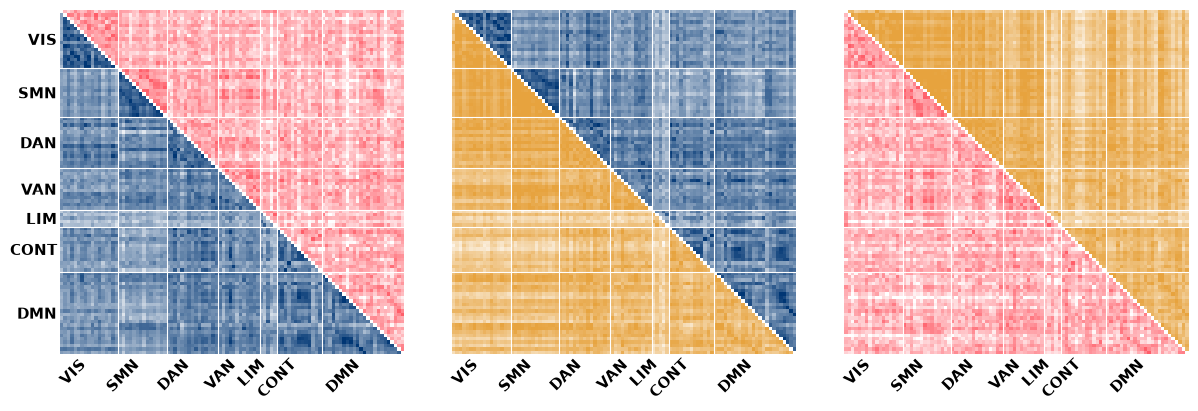

In [41]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Order parcels by network
network_map = (
    datasets["replication"][["Parcel", "Network"]]
    .drop_duplicates("Parcel")
    .set_index("Parcel")["Network"]
)

parcel_order = sorted(
    parcels,
    key=lambda p: (network_order.index(network_map[p]), p)
)

idx = np.array(parcel_order) - 1
ordered_networks = network_map.loc[parcel_order].to_numpy()

boundaries = np.r_[0, np.flatnonzero(
    ordered_networks[:-1] != ordered_networks[1:]
) + 1, len(parcels)]

centers = (boundaries[:-1] + boundaries[1:] - 1) / 2
labels = ordered_networks[boundaries[:-1]]

# Reorder correlation matrices
ordered = {
    name: matrix[np.ix_(idx, idx)]
    for name, matrix in matrices.items()
}


def plot_split_matrix(ax, upper_name, lower_name, show_ylabels=True):
    n = len(parcels)
    upper = np.ma.masked_where(
        ~np.triu(np.ones((n, n), dtype=bool), 1),
        ordered[upper_name]
    )
    lower = np.ma.masked_where(
        ~np.tril(np.ones((n, n), dtype=bool), -1),
        ordered[lower_name]
    )

    for matrix, name in [(upper, upper_name), (lower, lower_name)]:
        ax.imshow(
            matrix, cmap=cmaps[name], norm=norm,
            interpolation="none"
        )

    for b in boundaries[1:-1]:
        ax.axhline(b - 0.5, color="white", lw=0.8)
        ax.axvline(b - 0.5, color="white", lw=0.8)

    ax.set_xticks(centers, network_labels, rotation=45, ha="right", fontweight="bold", fontsize=TICKSIZE)
    ax.set_yticks(centers, network_labels if show_ylabels else [], fontweight="bold", fontsize=TICKSIZE)
    ax.tick_params(length=0, labelsize=11, pad=2)

    for spine in ax.spines.values():
        spine.set_visible(False)

# Dataset colors
cmaps = {
    "replication": cmap_replication,
    "discovery": cmap_discovery,
    "robustness": cmap_robustness
}

# Upper triangle = y dataset; lower triangle = x dataset
comparisons = [
    ("replication", "discovery"),
    ("discovery", "robustness"),
    ("robustness", "replication")
]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

for i, (upper, lower) in enumerate(comparisons):
    plot_split_matrix(axes[i], upper, lower, show_ylabels=(i == 0))

fig.subplots_adjust(
    left=0.06, right=0.91,
    bottom=0.16, top=0.98, wspace=0.08
)

plt.show()

fig.savefig(
    f"{output_path}/G_correlation_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

### Scatterplots

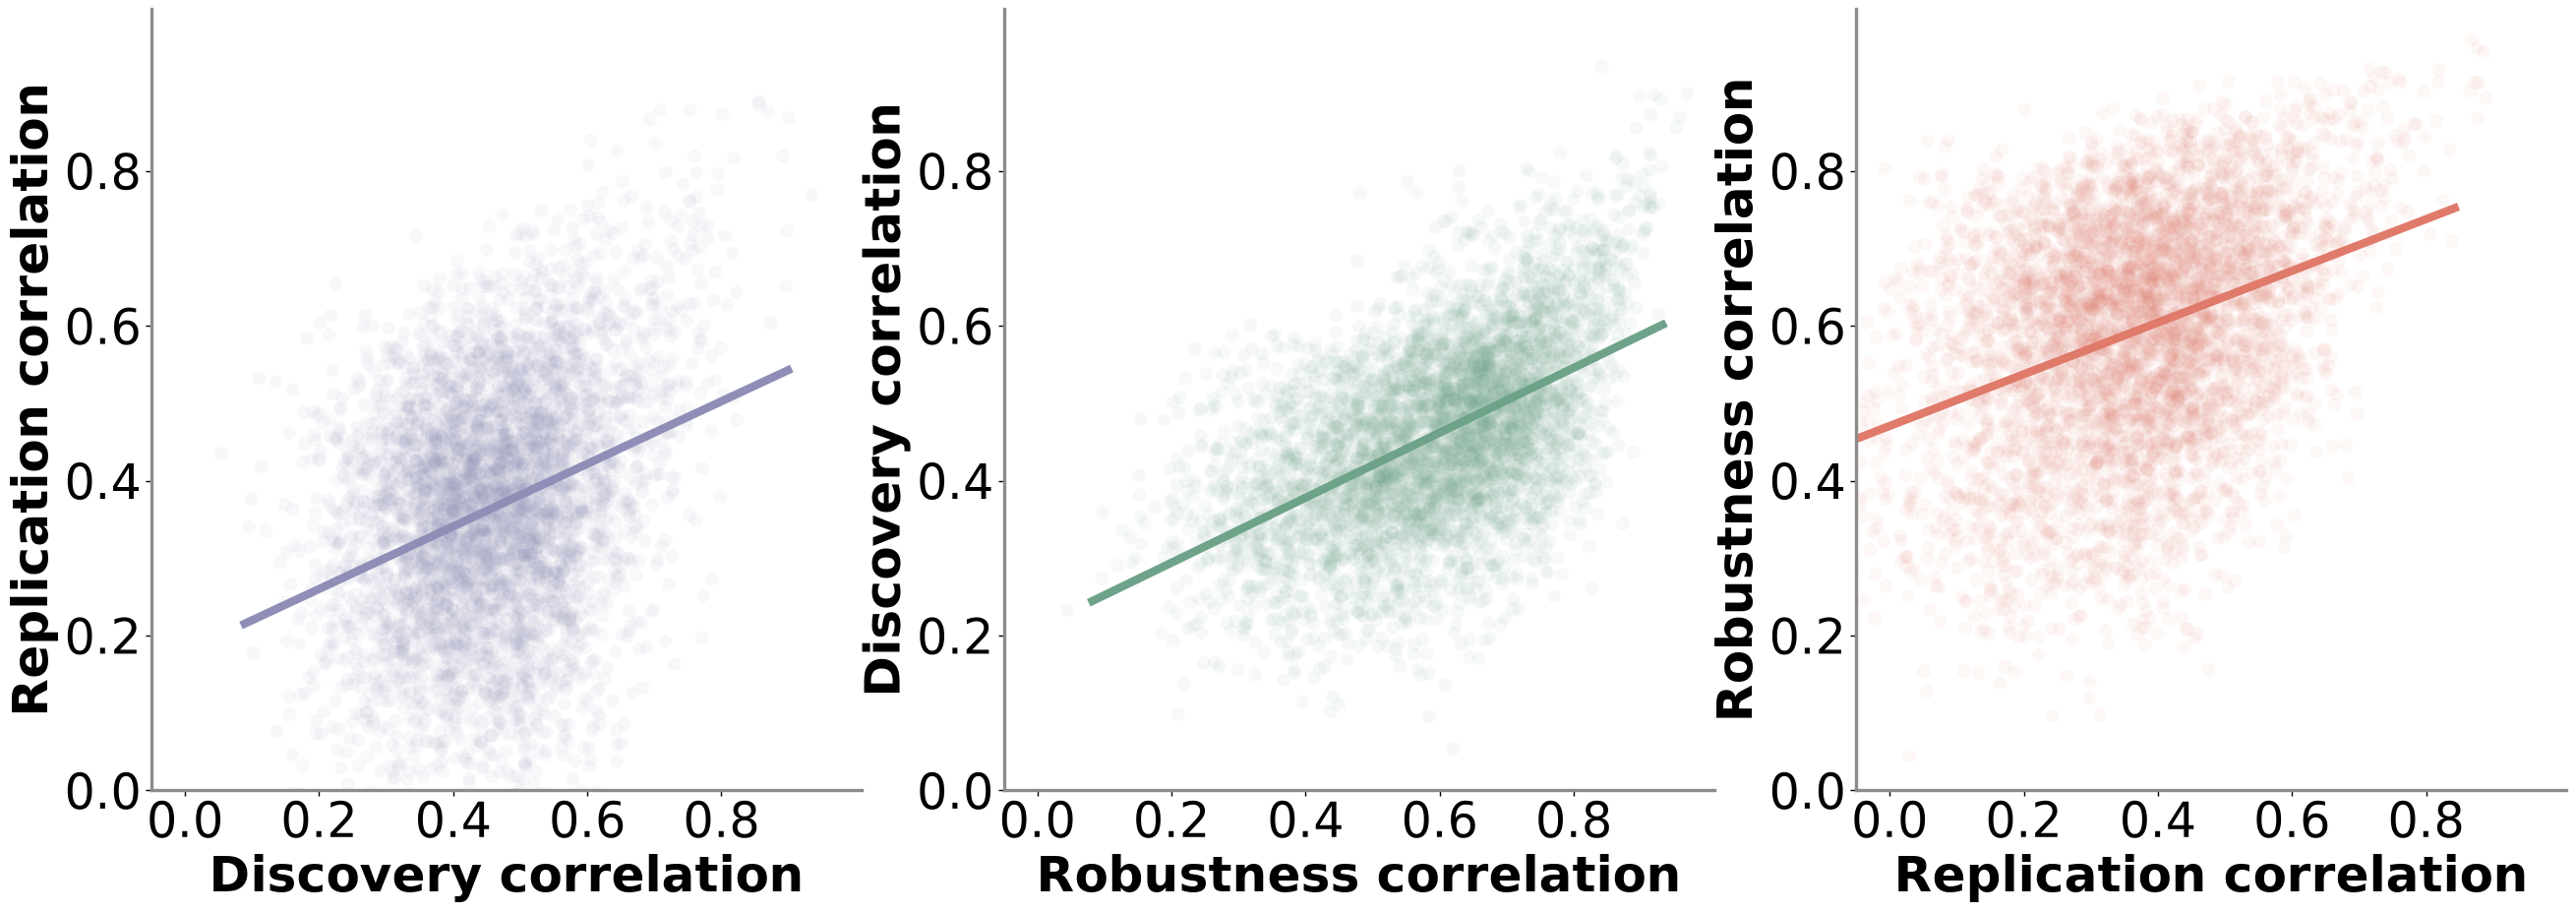

In [8]:
# Pair specifications
pairs = [
    ("discovery", "replication", "#8E8EB6"),
    ("robustness", "discovery", "#6EA38A"),
    ("replication", "robustness", "#E07A6A")
]

labels = {
    "discovery": "Discovery",
    "replication": "Replication",
    "robustness": "Robustness"
}

# Common axis limits
all_values = np.concatenate(list(correlations.values()))
global_max = np.nanmax(all_values)

fig, axes = plt.subplots(1, 3, figsize=(26.4, 10))

for ax, (x_name, y_name, color) in zip(axes, pairs):
    x, y = correlations[x_name], correlations[y_name]
    valid = np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]

    # Scatter and regression
    ax.scatter(x, y, s=100, alpha=0.06, color=color, edgecolors="none")

    slope, intercept = np.polyfit(x, y, 1)
    margin = 0.04 * (x.max() - x.min())
    x_line = np.linspace(x.min() + margin, x.max() - margin, 200)
    ax.plot(x_line, slope * x_line + intercept, color=color, lw=6)

    # Axes
    ax.set(xlim=(-0.05, global_max + 0.04),
           ylim=(0, global_max + 0.04))
    ax.set_xlabel(f"{labels[x_name]} correlation", fontsize=36, fontweight="bold")
    ax.set_ylabel(f"{labels[y_name]} correlation", fontsize=36, fontweight="bold")

    ax.set_xticks(np.arange(0, 1, 0.2))
    ax.set_yticks(np.arange(0, 1, 0.2))
    ax.tick_params(labelsize=35, width=1, length=4)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set(color="0.55", linewidth=2.4)

    ax.set_box_aspect(1.1)

fig.subplots_adjust(
    left=0.065, right=0.995,
    bottom=0.16, top=0.98, wspace=0.2
)

plt.show()

fig.savefig(
    f"{output_path}/G_correlation_scatterplots.png",
    dpi=600,
    bbox_inches="tight"
)